# B2. Pembentukan Citra dan Ruang Warna (SIMUTEH, SEED 1014)

In [7]:
import sys
sys.path.append("../src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil, kontras_bercak

## Langkah 2.1 Pemeriksaan lembar hitung manual dengan kode
Langkah tulisan tangan ada di laporan (Lampiran A). Sel ini hanya memeriksa angkanya.

In [8]:
f, pix, X = 4.0, 0.0014, 5.0
for Z in (300, 600):
    x = f * X / Z
    print(f"Z={Z} mm: x={x:.4f} mm = {x/pix:.1f} piksel")
print("c) Z maks utk 10 piksel (foto asli): %.1f mm" % (f * X / (10 * pix)))
skala = 640 / 4000
print("d) diameter setelah diperkecil (Z=300): %.2f piksel" % (f*X/300/pix*skala))
print("   Z maks utk 10 piksel setelah diperkecil: %.1f mm" % (f * X / (10 / skala * pix)))
asli = 4000*3000*3; warna = 640*480*3; abu = 640*480
print("e) asli:", asli, "byte =", asli/1e6, "MB | 640x480 warna:", warna, "byte | abu:", abu, "byte")
print("   300 foto:", 300*asli/1e9, "GB (", 300*asli/2**30, "GiB )")
bercak, daun = np.array([196,178,86]), np.array([52,136,60])
Y = lambda c: 0.299*c[0] + 0.587*c[1] + 0.114*c[2]
print("f) Y bercak=%.3f Y daun=%.3f selisih=%.3f" % (Y(bercak), Y(daun), Y(bercak)-Y(daun)))
px = np.array([[bercak[::-1], daun[::-1]]], np.uint8)  # BGR
print("   cvtColor gray:", cv2.cvtColor(px, cv2.COLOR_BGR2GRAY)[0])
print("   Hue OpenCV (bercak, daun):", cv2.cvtColor(px, cv2.COLOR_BGR2HSV)[0, :, 0])
print("   HSV penuh (bercak, daun):", cv2.cvtColor(px, cv2.COLOR_BGR2HSV)[0].tolist())

Z=300 mm: x=0.0667 mm = 47.6 piksel
Z=600 mm: x=0.0333 mm = 23.8 piksel
c) Z maks utk 10 piksel (foto asli): 1428.6 mm
d) diameter setelah diperkecil (Z=300): 7.62 piksel
   Z maks utk 10 piksel setelah diperkecil: 228.6 mm
e) asli: 36000000 byte = 36.0 MB | 640x480 warna: 921600 byte | abu: 307200 byte
   300 foto: 10.8 GB ( 10.058283805847168 GiB )
f) Y bercak=172.894 Y daun=102.220 selisih=70.674
   cvtColor gray: [173 102]
   Hue OpenCV (bercak, daun): [25 63]
   HSV penuh (bercak, daun): [[25, 143, 196], [63, 158, 136]]


## Langkah 2.3 Kanal warna (teh_041, berat, normal)

KB kanal B   : 1.24
KB kanal G   : 1.02
KB kanal R   : 7.32
KB kanal Gray: 3.94
KB kanal H   : 4.97
KB kanal S   : 0.68
KB kanal V   : 2.21


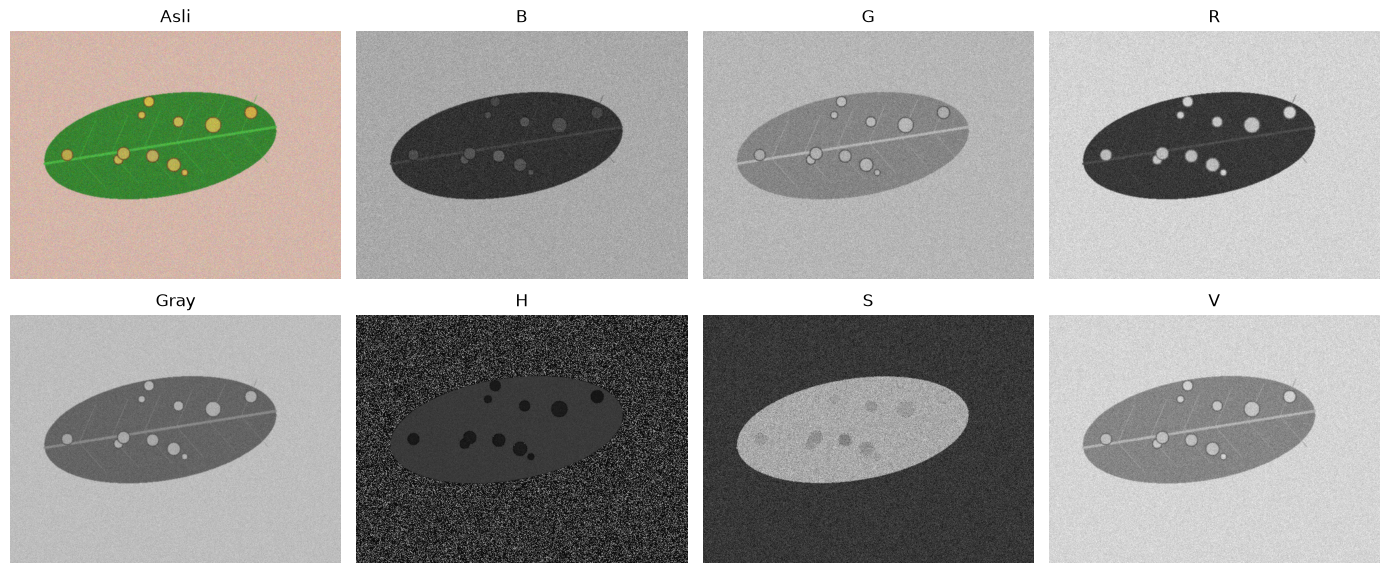

In [3]:
nama = "teh_041.png"
img = baca(f"../data/sintetis/citra/{nama}")
md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
b, g, r = cv2.split(img)
h, s, v = cv2.split(hsv)
kanal = {"B": b, "G": g, "R": r, "Gray": gray, "H": h, "S": s, "V": v}
tampil([img] + list(kanal.values()), ["Asli"] + list(kanal.keys()),
       baris=2, ukuran=(14, 6))
plt.savefig("../hasil/b2_panel_kanal.png", dpi=100)
for nm, c in kanal.items():
    print(f"KB kanal {nm:4s}: {kontras_bercak(c, md, mb):.2f}")

## Langkah 2.4 Sampling dan kuantisasi

fx=0.5: ukuran (240, 320), KB=5.23
fx=0.2: ukuran (96, 128), KB=4.87
fx=0.1: ukuran (48, 64), KB=3.27
fx=0.05: ukuran (24, 32), KB=1.30
k=1: 2 level, KB=3.95
k=2: 4 level, KB=4.03
k=3: 7 level, KB=2.70
k=4: 12 level, KB=3.66
k=8: 166 level, KB=3.94


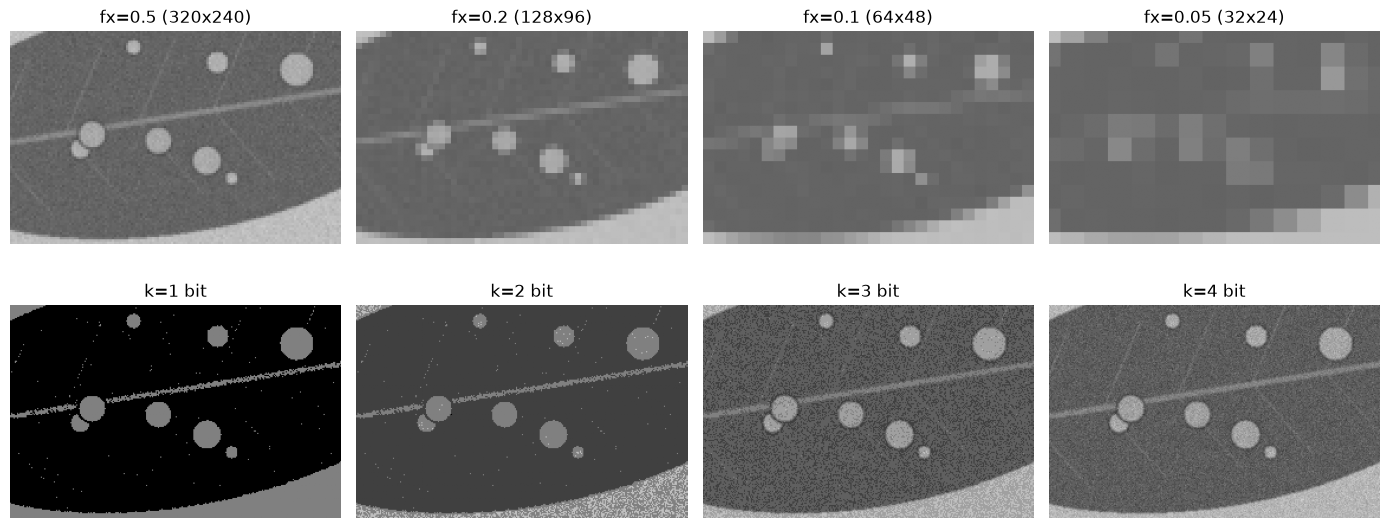

In [4]:
rows = []
fig, ax = plt.subplots(2, 4, figsize=(14, 6))
for i, fx in enumerate([0.5, 0.2, 0.1, 0.05]):
    kecil = cv2.resize(gray, None, fx=fx, fy=fx, interpolation=cv2.INTER_AREA)
    besar = cv2.resize(kecil, gray.shape[::-1], interpolation=cv2.INTER_NEAREST)
    kb = kontras_bercak(besar, md, mb)
    print(f"fx={fx}: ukuran {kecil.shape}, KB={kb:.2f}")
    rows.append(["sampling fx=%s" % fx, "%dx%d" % kecil.shape[::-1], round(kb, 2)])
    ax[0, i].imshow(besar[150:330, 150:430], cmap="gray", vmin=0, vmax=255)
    ax[0, i].set_title(f"fx={fx} ({kecil.shape[1]}x{kecil.shape[0]})"); ax[0, i].axis("off")
for i, k in enumerate([1, 2, 3, 4]):
    langkah = 256 // (2 ** k)
    kuant = (gray // langkah) * langkah
    ax[1, i].imshow(kuant[150:330, 150:430], cmap="gray", vmin=0, vmax=255)
    ax[1, i].set_title(f"k={k} bit"); ax[1, i].axis("off")
plt.tight_layout(); plt.savefig("../hasil/b2_sampling_kuantisasi.png", dpi=100)
for k in [1, 2, 3, 4, 8]:
    langkah = 256 // (2 ** k)
    kuant = (gray // langkah) * langkah
    kb = kontras_bercak(kuant, md, mb)
    print(f"k={k}: {len(np.unique(kuant))} level, KB={kb:.2f}")
    rows.append(["kuantisasi k=%d" % k, "%d level" % len(np.unique(kuant)), round(kb, 2)])
pd.DataFrame(rows, columns=["eksperimen", "keterangan", "KB"]).to_csv("../hasil/b2_sampling_kuantisasi.csv", index=False)

## Langkah 2.5 Rerata KB per kanal dan kondisi (kelas berat)

In [5]:
def semua_kanal(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    b, g, r = cv2.split(img); h, s, v = cv2.split(hsv)
    return {"B": b, "G": g, "R": r,
            "Gray": cv2.cvtColor(img, cv2.COLOR_BGR2GRAY),
            "H": h, "S": s, "V": v}

label = pd.read_csv("../data/sintetis/label.csv")

def tabel_kelas(nama_kelas):
    baris = []
    for _, d in label[label.kelas == nama_kelas].iterrows():
        im = baca(f"../data/sintetis/citra/{d.nama_file}")
        m_d = cv2.imread(f"../data/sintetis/mask_daun/{d.nama_file}", 0)
        m_b = cv2.imread(f"../data/sintetis/mask_bercak/{d.nama_file}", 0)
        kb = {k: kontras_bercak(c, m_d, m_b) for k, c in semua_kanal(im).items()}
        kb["kondisi"] = d.kondisi_cahaya
        baris.append(kb)
    t = pd.DataFrame(baris).groupby("kondisi").mean().round(2)
    return t.loc[["normal", "gelap", "terang", "kontras_rendah", "bayangan"]]

tabel_kb = tabel_kelas("berat")
print(tabel_kb)
tabel_kb.to_csv("../hasil/b2_kb_kanal.csv")
print("rerata semua kondisi:"); print(tabel_kb.mean().round(2))

                   B     G      R  Gray     H     S     V
kondisi                                                  
normal          2.15  0.54   8.89  4.09  6.98  1.58  1.99
gelap           1.31  0.78  11.98  4.25  7.75  1.22  2.77
terang          1.66  1.27   7.51  4.42  5.45  0.60  2.49
kontras_rendah  0.68  0.37   3.35  1.90  1.46  0.19  1.28
bayangan        1.43  0.25   5.36  1.62  4.94  1.13  0.91
rerata semua kondisi:
B       1.45
G       0.64
R       7.42
Gray    3.26
H       5.32
S       0.94
V       1.89
dtype: float64


## Langkah 2.6 Kelas ringan dan kanal terbaik

                   B     G     R  Gray     H     S     V
kondisi                                                 
normal          1.69  0.55  8.65  3.02  8.06  1.34  1.16
gelap           1.04  0.85  8.79  2.75  6.39  1.15  1.99
terang          1.63  0.45  5.40  2.50  4.52  0.99  0.99
kontras_rendah  0.78  0.30  3.49  1.56  2.16  0.38  0.86
bayangan        1.10  0.43  4.43  1.30  4.18  0.66  0.87
rerata semua kondisi:
B       1.25
G       0.52
R       6.15
Gray    2.23
H       5.06
S       0.90
V       1.17
dtype: float64
Kanal terbaik (rerata KB kelas berat): R


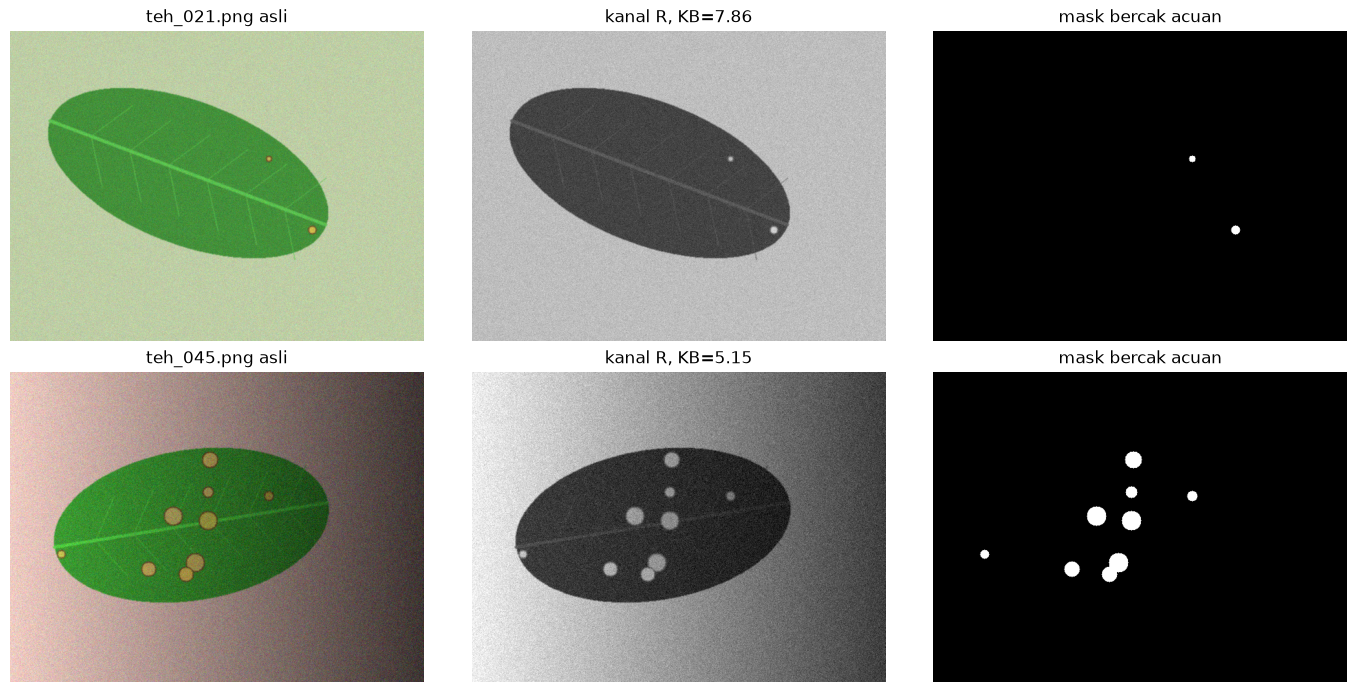

In [6]:
tabel_ringan = tabel_kelas("ringan")
print(tabel_ringan)
tabel_ringan.to_csv("../hasil/b2_kb_kanal_ringan.csv")
print("rerata semua kondisi:"); print(tabel_ringan.mean().round(2))
terbaik = tabel_kb.mean().idxmax()
print("Kanal terbaik (rerata KB kelas berat):", terbaik)
fig, ax = plt.subplots(2, 3, figsize=(14, 7))
for i, nm in enumerate(["teh_021.png", "teh_045.png"]):
    im = baca(f"../data/sintetis/citra/{nm}")
    m_d = cv2.imread(f"../data/sintetis/mask_daun/{nm}", 0)
    m_b = cv2.imread(f"../data/sintetis/mask_bercak/{nm}", 0)
    k = semua_kanal(im)[terbaik]
    ax[i, 0].imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); ax[i, 0].set_title(nm + " asli")
    ax[i, 1].imshow(k, cmap="gray", vmin=0, vmax=255)
    ax[i, 1].set_title(f"kanal {terbaik}, KB={kontras_bercak(k, m_d, m_b):.2f}")
    ax[i, 2].imshow(m_b, cmap="gray"); ax[i, 2].set_title("mask bercak acuan")
    for a in ax[i]: a.axis("off")
plt.tight_layout(); plt.savefig("../hasil/b2_kanal_terbaik.png", dpi=100)